# slot_chain_check:名字 → 3D 位置,不训练,两个现成模块串起来

**问题**:「物体槽」架构的核心是两步:dino.txt 把名字对到 patch,点提示头把 patch 对到 3D 位置。两步各自测过,没接在一起跑过。这里接起来,和直接训练的「类别→位置」probe 比。

**做法**(脚本 `jepa3d/tools/chain_teacher_point.py`,任务 13069,不训练)
- 数据:与各 probe 相同的验证样本,229 个场景 × 3 个种子,每个样本 8 张图,场景内唯一的物体。
- 点提示头:`outputs/geo_probe/point_3drae_real/final.pt`,输入一个 patch 的 DINOv2 特征和射线,在冻结 3DRAE 的 token 上做注意力,输出 3D 位置。原样使用。
- 只换点提示的来源:

| 来源 | 含义 |
|---|---|
| `gt` | 物体中心的真实投影(点提示头训练和评估时的用法) |
| `box` | 射线穿过物体 3D 框的随机一个 patch:对象对,但不在中心 |
| `teacher` | dino.txt 选的 patch,去均值打分 + 8 模板(诊断里最好的组合) |
| `raw` | dino.txt 选的 patch,原始相似度 |
| `random` | 随机 patch |

对照:`类别→位置 probe`(`outputs/geo_probe/real`),在 913 个训练场景上用框监督训练出来的。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ["jpeg"]

m = json.load(open("../results/chain.json"))["metrics"]
probe = json.load(open("../results/category_probe/final_metrics.json"))["eval_real"]

def f(v, pct=False):
    k, d, u = (100, 1, "%") if pct else (1, 2, "")
    return f'{k * v["value"]:.{d}f}{u} [{k * v["ci95"][0]:.{d}f}, {k * v["ci95"][1]:.{d}f}]'

LABEL = {"gt": "gt:真实中心", "box": "box:框内随机 patch", "teacher": "teacher:dino.txt 去均值", "raw": "raw:dino.txt 原始", "random": "random"}

## 1. 与类别→位置 probe 比(可见物体,口径相同)

`gt` 和 `box` 只能用于有提示的物体,物体数少一些。方括号是按场景重采样的 95% 置信区间。

In [2]:
rows = [{"方法": "类别→位置 probe(训练过)", "物体数": probe["visible/position_m"]["n"], "位置误差中位数 (m)": f(probe["visible/position_m"]),
         "象限准确率": f(probe["visible/quadrant_acc"], True), "左右后准确率": f(probe["visible/lrb_acc"], True),
         "两两距离误差 (m)": f(probe["visible/distance_m"])}]
for s in ("teacher", "raw", "box", "gt", "random"):
    rows.append({"方法": "串联," + LABEL[s], "物体数": m[f"{s}/visible/position_m"]["n"], "位置误差中位数 (m)": f(m[f"{s}/visible/position_m"]),
                 "象限准确率": f(m[f"{s}/visible/quadrant_acc"], True), "左右后准确率": f(m[f"{s}/visible/lrb_acc"], True),
                 "两两距离误差 (m)": f(m[f"{s}/visible/distance_m"])})
pd.DataFrame(rows)

,方法,物体数,位置误差中位数 (m),象限准确率,左右后准确率,两两距离误差 (m)
0,类别→位置 probe(训练过),5620,"0.95 [0.86, 1.05]","45.6% [43.3, 48.9]","54.5% [52.3, 57.1]","0.64 [0.57, 0.71]"
1,"串联,teacher:dino.txt 去均值",5620,"0.67 [0.62, 0.72]","50.6% [48.5, 52.5]","59.5% [57.8, 61.4]","0.53 [0.48, 0.59]"
2,"串联,raw:dino.txt 原始",5620,"0.85 [0.78, 0.92]","44.1% [42.3, 46.6]","53.5% [51.5, 55.5]","0.65 [0.60, 0.72]"
3,"串联,box:框内随机 patch",5305,"0.47 [0.44, 0.49]","74.2% [73.0, 75.3]","80.7% [79.9, 81.7]","0.32 [0.30, 0.34]"
4,"串联,gt:真实中心",4393,"0.27 [0.25, 0.29]","84.3% [82.8, 85.6]","88.4% [87.3, 89.4]","0.21 [0.19, 0.23]"
5,"串联,random",5620,"2.12 [2.02, 2.21]","31.3% [30.9, 31.8]","41.9% [41.5, 42.4]","0.95 [0.89, 1.02]"


## 2. 误差从哪来(中心在视野内的物体)

`指中` = 所选 patch 的射线穿过物体的 3D 框。

In [3]:
rows = []
for s in ("teacher", "raw", "random"):
    rows.append({"来源": LABEL[s], "物体数": m[f"{s}/in_view/position_m"]["n"], "指中率": f(m[f"{s}/in_view/in_box_acc"], True),
                 "全部 (m)": f(m[f"{s}/in_view/position_m"]), "指中时 (m)": f(m[f"{s}/in_view_hit/position_m"]),
                 "没指中时 (m)": f(m[f"{s}/in_view_miss/position_m"])})
display(pd.DataFrame(rows))
rows = []
for s in ("gt", "box", "teacher", "raw"):
    rows.append({"来源": LABEL[s], **{label: f(m[f"{s}/in_view_size_{g}/position_m"]) for g, label in
                                    (("lt0.5m", "最长边 < 0.5 m"), ("0.5-1m", "0.5–1 m"), ("gt1m", "> 1 m"))}})
pd.DataFrame(rows)

,来源,物体数,指中率,全部 (m),指中时 (m),没指中时 (m)
0,teacher:dino.txt 去均值,4949,"62.2% [60.0, 64.2]","0.59 [0.54, 0.66]","0.41 [0.38, 0.43]","1.78 [1.65, 1.94]"
1,raw:dino.txt 原始,4949,"46.6% [44.2, 48.7]","0.78 [0.72, 0.86]","0.42 [0.40, 0.44]","1.85 [1.70, 1.97]"
2,random,4949,"6.0% [5.3, 6.8]","2.09 [1.98, 2.19]","0.58 [0.52, 0.66]","2.18 [2.06, 2.30]"


,来源,最长边 < 0.5 m,0.5–1 m,> 1 m
0,gt:真实中心,"0.26 [0.25, 0.29]","0.26 [0.24, 0.29]","0.29 [0.27, 0.32]"
1,box:框内随机 patch,"0.31 [0.28, 0.32]","0.39 [0.37, 0.43]","0.60 [0.57, 0.64]"
2,teacher:dino.txt 去均值,"0.53 [0.46, 0.67]","0.47 [0.43, 0.55]","0.66 [0.62, 0.70]"
3,raw:dino.txt 原始,"1.43 [1.30, 1.59]","0.69 [0.57, 0.80]","0.65 [0.61, 0.69]"


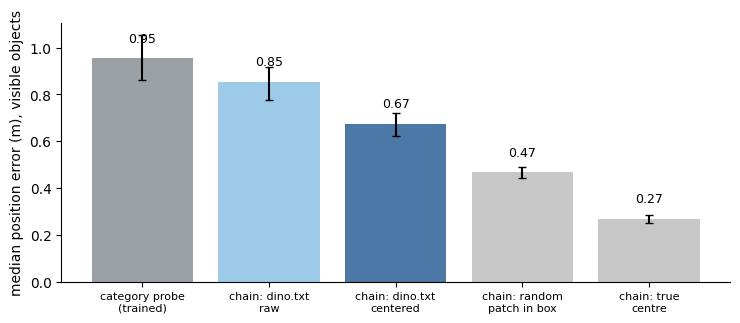

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
names = ["category probe\n(trained)", "chain: dino.txt\nraw", "chain: dino.txt\ncentered", "chain: random\npatch in box", "chain: true\ncentre"]
vals = [probe["visible/position_m"]] + [m[f"{s}/visible/position_m"] for s in ("raw", "teacher", "box", "gt")]
y = [v["value"] for v in vals]
err = [[v["value"] - v["ci95"][0] for v in vals], [v["ci95"][1] - v["value"] for v in vals]]
ax.bar(range(5), y, yerr=err, capsize=3, color=["#9aa0a6", "#9ecae9", "#4c78a8", "#c7c7c7", "#c7c7c7"])
for i, v in enumerate(y):
    ax.text(i, v + 0.07, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(5)); ax.set_xticklabels(names, fontsize=8); ax.set_ylabel("median position error (m), visible objects")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 3. 结论

1. **串联可行,不训练就好于训练过的 probe。** 位置误差 0.67 m 对 0.95 m,置信区间不重叠。象限准确率 50.6% 对 45.6%,区间有少量重叠,改善较小。
2. **瓶颈在 dino.txt 的指中率,不在点提示头。** 指中时误差 0.41 m,没指中时 1.78 m;指中率 62%。
3. **点提示头对「不在中心的点」能用但会变差。** 框内随机 patch 0.43 m(中心 0.27 m),大物体更明显(0.60 m)。它是只用中心点训练的。
4. **上限清楚。** 对象全部指对而位置不居中:0.47 m / 74%;指到中心:0.27 m / 84%。现在是 0.67 m / 51%。
5. **去均值打分在串联里同样有效**:0.85 m → 0.67 m。

## 4. 可以改进的两处(都没做)

- 提高指中率:现在只取一个最高分 patch。可以用多个视角的高分 patch 互相印证(几条射线是否交于一处),或把相似度图当作权重取质心。
- 让点提示头适应不居中的点:训练时把提示点在框内随机取,而不是只取中心。

## 5. 局限

- 只测了场景内唯一的物体,同类多个实例的情况没有测。
- 象限这类方向指标对「指错对象」很敏感:两个物体里错一个,这一对的方向就错。38% 没指中是方向指标改善小的主要原因,这是推断,没有单独验证。
- 这里只证明了「名字 → 位置」这条链路。把物体槽接进 predictor 后,predictor 会不会用它,要另做实验(real − shuffled)。
- 点提示头只跑了一个种子的权重。